# Neutral penetration analysis

We have previously identified the discrepency of neutral penetration level between fluid and kinetic model. 

In [1]:
# %matplotlib widget


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os, sys, pathlib, shlex, subprocess
import xbout
import scipy
import xhermes
# from xhermes import *


sys.path.append(r"/Users/zero/workspace/phd_work/hms_output/sdtools")
sys.path.append(r"/Users/zero/workspace/phd_work/hms_output/hermes3-2dplots/pltool")
# sys.path.append(r"/users/jpm590/2dspace/post-processing/sdtools/")
# sys.path.append(r"/users/jpm590/2dspace/post-processing/xBOUT/")

# from xbout.load import *
# from xbout.boutdataarray import *

from hermes3.utils import *

from code_comparison.solps_pp import *
from hermes3.fluxes import *
from hermes3.case_db import *
from hermes3.load import *
from hermes3.named_selections import *
from hermes3.plotting import *
from hermes3.grid_fields import *
from hermes3.accessors import *
from hermes3.selectors import *
from common import setup_matplotlib, adapt_solps_conventions

%load_ext autoreload
%autoreload 2
print("Done")

Done


In [13]:
db = CaseDB(
    case_dir = r"/Users/zero/workspace/phd_work/hms_output",
    grid_dir = r"/Users/zero/workspace/phd_work/hms_output/gridfile"
)

toload = [
    dict(name="260717_highrsl_6e20_coreOO", id="260717_highrsl_6e20_coreOO", unnormalise_geom = True, use_xhermes = True, squash = True),
]

cs = {}
for case in toload:
    cs[case["name"]] = db.load_case_2D(case["id"], use_squash = case["squash"], verbose = True)

    cs[case["name"]].extract_2d_tokamak_geometry()

/Users/zero/workspace/phd_work/hms_output/xhermes/lib/python3.12/site-packages/boutdata/data.py:762: AlwaysWarning: While building x, y, z coordinate arrays, an exception occured: [Errno 2] No such file or directory: '"CDN_46895_260513_nowallpump_6e20.nc"'
Evaluating non-scalar options not available
  alwayswarn(


- Reading case 260717_highrsl_6e20_coreOO
-----------------------
- Looking for squash file
- Squash file found. squash date 08/27/2026, 21:44:52, dmp file date 08/07/2026, 03:50:02


/Users/zero/workspace/phd_work/hms_output/xhermes/lib/python3.12/site-packages/boutdata/data.py:762: AlwaysWarning: While building x, y, z coordinate arrays, an exception occured: 'PosixPath' object has no attribute 'split'
Evaluating non-scalar options not available
  alwayswarn(
/Users/zero/workspace/phd_work/hms_output/xBOUT/xbout/load.py:1294: UserWarning: Will drop all variables containing the dimensions 'closed_wall' because they are not recognised
  warn(



Unnormalising with xHermes


#### Choose your datatset

In [14]:
ds = cs["260717_highrsl_6e20_coreOO"].ds.isel(t=-1)

# SOLPS
solps_path = "../SOLPS_origin_1e21"
bal = SOLPScase(solps_path)
bal = adapt_solps_conventions(bal)

[]


##### Intergrate fields in domains
Get the volume of the region you want.

You could possibly choose ([reference](https://github.com/mikekryjak/sdtools/blob/4242b6f0a55edf66d0b6e6f706bb7dc8515eb143/hermes3/deprecated/stuff.py#L155)): 
```python 
    core = ds.hermesm.select_region("core_noguards")
    domain = ds.hermesm.select_region("all_noguards")
    domain_volume = domain["dv"].values.sum()
```

In [7]:
# Hermes-3 
domain = ds.hermesm.select_region("all_noguards")
Nd = domain["Nd"] 
dv = domain["dv"]
Nd_total = (Nd * dv).sum(["x", "theta"]).squeeze()
print(Nd.shape)
print(f"[Hermes-3] Neutral in domain = {Nd_total.values:.3e} ")
Nd_trans = domain["Nd"].transpose("theta","x")
print(f"Nd_trans shape :{Nd_trans.shape}")

# SOLPS
Na_guard  = bal.bal["Na"]
vol_guard = bal.g["vol"]
print(f"Na_guard shape :  {Na_guard.shape}")
# print(f"vol_guard shape :  {vol_guard.shape}")
pol = np.r_[1:71, 73:203] # poloidal: drop 0, 72, 73, 203
rad = np.r_[1:37]        # radial:   0, 37 are guard cell

vol = bal.g["vol"][pol,:][:,rad]          # [m^3], 去 guard cells
print(f"vol shape {vol.shape}")
Na  = bal.bal["Na"][pol,:][:, rad]          # atoms   [m^-3]
# print(Na.values)
print(f"Na shape :  {Na.shape}")
Na_total = (Na * vol).sum()

print(f"[SOLPS] Neutral atoms in domain = {Na_total:.3e} ")
print(f"relative diff = {(Nd_total.values-Na_total)/Na_total}")


(36, 200)
[Hermes-3] Neutral in domain = 2.772e+18 
Nd_trans shape :(200, 36)
Na_guard shape :  (204, 38)
vol shape (200, 36)
Na shape :  (200, 36)
[SOLPS] Neutral atoms in domain = 2.252e+18 
relative diff = 0.2312678657457756


In [39]:

# Hermes-3 
# domain = ds.hermesm.select_region("all_noguards")
# Nd = domain["Nd"] 
# dv = domain["dv"]
# Nd_total = (Nd * dv).sum(["x", "theta"]).squeeze()
# print(Nd.shape)
# print(f"[Hermes-3] Neutral in domain = {Nd_total.values:.3e} ")
# Nd_trans = domain["Nd"].transpose("theta","x")
# print(f"Nd_trans shape :{Nd_trans.shape}")

# Choose region manually
Nd_guard = ds["Nd"].transpose("theta","x")
print(f"Nd_guard shape: {Nd_guard.shape}")
pol_h = np.r_[2:72, 76:206] # poloidal: drop 0 1 , 72 73, 74 75 , 206 207
rad_h = np.r_[2:38]
# print(pol_h, rad_h)    
Nd = Nd_guard[pol_h, :][:, rad_h]
print(f"Nd shape: {Nd.shape}")
print(f"1st element is {Nd[0,0].values}")


# Nd_guard = ds["Nd"]
# print(f"Nd_guard shape: {Nd_guard.shape}")
# pol_h = np.r_[2:72, 76:206] # poloidal: drop 0 1 , 72 73, 74 75 , 206 207
# rad_h = np.r_[2:38]
# # print(pol_h, rad_h)    
# Nd = Nd_guard[rad_h, :][:, pol_h]
# print(f"Nd shape: {Nd.shape}")
# print(f"1st element is {Nd[0,0].values}")

# SOLPS
Na_guard  = bal.bal["Na"]
vol_guard = bal.g["vol"]
print(f"Na_guard shape :  {Na_guard.shape}")
# print(f"vol_guard shape :  {vol_guard.shape}")

# Make an index element 
# pol : 1, 2, 3, 4, 5, ... 71, 74, 75 ...., 202
# rad : 1, 2, 3, ... ,36
pol = np.r_[1:72, 74:203] # poloidal: drop 0, 72, 73, 203
rad = np.r_[1:37]        # radial:   0, 37 are guard cell

# vol = bal.g["vol"][pol,:][:,rad]          # [m^3], 去 guard cells
# print(f"vol shape {vol.shape}")
Na  = bal.bal["Na"][pol,:][:, rad]          # atoms   [m^-3]
# print(Na.values)
print(f"Na shape :  {Na.shape}")
print(f"1st element is {Na[0,0]}")
# Na_total = (Na * vol).sum()

# print(f"[SOLPS] Neutral atoms in domain = {Na_total:.3e} ")




Nd_guard shape: (208, 40)
Nd shape: (200, 36)
1st element is 1.4304043495540242e+18
Na_guard shape :  (204, 38)
Na shape :  (200, 36)
1st element is 3.5915800754196864e+17


1.0712463420120556e+18
Nd_full shape: (208, 40)


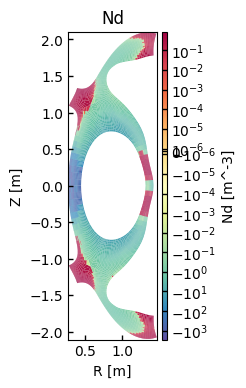

In [5]:
# Get the shape from original array and fill nan into the array
# np.full(shape, fiiling values)

# full_arr = np.full(ds["Nd"].shape, np.nan)
# Nd_transp = Nd.transpose("theta","x")
# print(f"Nd_transp shape = {Nd_transp.shape}")
# # Specify the location by ix and fill in the values into the array
# full_arr[np.ix_(pol_h, rad_h)] = np.asarray(Nd_transp) - np.asarray(Na)
# print(f"Nd_full shape: {full_arr.shape}")


# You can only use Hermes-3's variable to do transpose because you know the they 
# Can be transposed by "x" and "theta"
diff_full_arr = np.full(ds["Nd"].transpose("theta","x").shape, np.nan)
# Specify the location by ix and fill in the values into the array
diff_full_arr[np.ix_(pol_h, rad_h)] = np.asarray(Nd) - np.asarray(Na)
print(diff_full_arr[2,2])
print(f"Nd_full shape: {diff_full_arr.shape}")




# To get the full dataset for the arrary
diff_full = ds["Nd"].transpose("theta", "x").copy(data=diff_full_arr) 
diff_norm = diff_full/ds["Nd"].transpose("theta", "x")
fig, ax = plt.subplots()
# diff_norm.bout.polygon(ax=ax, cmap="RdBu_r", antialias=True,
diff_norm.bout.polygon(ax=ax, cmap="Spectral_r", antialias=True,
                logscale=True, separatrix=False, )
fig.savefig("diff.pdf")







Explanation:

Hermes-3 has larger amount of neutral at target comparing to SOLPS. At puff location, neutrals are more spread out than SOLPS

If we plot neutral atom seperately: 

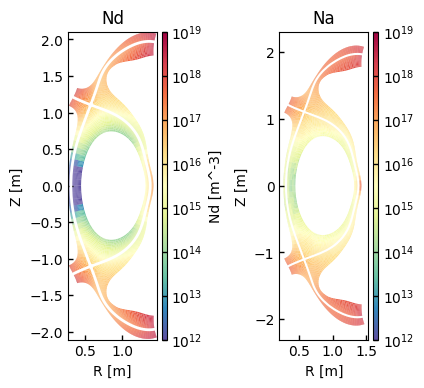

In [10]:

fig, ax = plt.subplots(1,2)
vmin = 1e12
vmax = 1e19
ds["Nd"].hermes.clear_guards().bout.polygon(
                ax=ax[0], cmap="Spectral_r", antialias=True,
                logscale=True, vmin = vmin, vmax=vmax)
bal.plot_2d("Na", ax=ax[1], cmap="Spectral_r", antialias=True,
                logscale=True, separatrix=True,vmin=vmin, vmax=vmax )




## Compare Vpol

Raw pfluxa (an array): [ 3.3138810e+21  2.7741974e+21  2.7564411e+21 ... -3.5400277e+21
 -3.3578369e+21 -3.2268148e+21]
pfluxa size = 7272, nx = 204, ny = 38, nx*ny = 7752


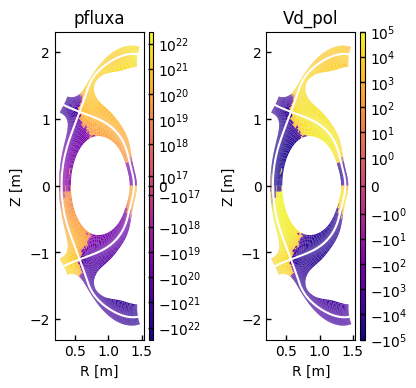

In [6]:
# Extract pfluxa from fort.44 and pad to (nx, ny)
import numpy as np
import builtins
filename = solps_path + "/fort.44"
var_name = "pfluxa"
with builtins.open(filename, 'r') as f:
    lines = f.readlines()

data_lines = []
found = False
for line in lines:
    if line.startswith(f"*eirene data field {var_name}"):
        found = True
        continue
    if found:
        if line.startswith("*"):
            break
        data_lines.append(line)

data = []
for line in data_lines:
    data.extend([float(x) for x in line.split()])

pfluxa = np.array(data)
print(f"Raw pfluxa (an array): {pfluxa}")

# Number of cells in balance.nc
nx, ny = bal.g["nx"], bal.g["ny"]
print(f"pfluxa size = {pfluxa.size}, nx = {nx}, ny = {ny}, nx*ny = {nx*ny}")
# print(f"Shape of pfluxa from fort.44: {np.shape(pfluxa)}")

# fort.44 outputs without guard cells: shape is (nx-2, ny-2)
# Fortran order ('F') means first dimension (poloidal) varies fastest.
pfluxa_inner = pfluxa.reshape((nx-2, ny-2), order='F')
# print(f"pfluxa_inner: {pfluxa_inner}")


# Pad with zeros to match SOLPS grid shape (nx, ny)
pfluxa_padded = np.zeros((nx, ny))
pfluxa_padded[1:-1, 1:-1] = pfluxa_inner
# print(pfluxa_padded)


fig, ax = plt.subplots(1,2)
# Plot using bal's plot_2d
# We need to flatten it since SOLPScase plot_2d expects a flattened array or internal data
try:
    # plot_2d uses the parameter as a title, and data for the values if provided
    bal.plot_2d(var_name, ax=ax[0], data=pfluxa_padded, logscale=True, cmap="plasma")
except Exception as e:
    print(f"Error plotting: {e}")



# --- Velocity Calculation ---
# Get Neutral Density from your SOLPScase (shape is already nx, ny)
Nd = bal.bal["Na"]
# Do a safe division: Vd = pfluxa / Nd (outputs 0 where Nd is 0)
Vd_pol = np.divide(pfluxa_padded, Nd, out=np.zeros_like(pfluxa_padded), where=(Nd!=0))
# Plot the new velocity array!
bal.plot_2d( "Vd_pol", ax=ax[1],data=Vd_pol, logscale=True,vmin= - 1e5, vmax=1e5, cmap="plasma")

##### Derive Vd_pol from Hermes-3

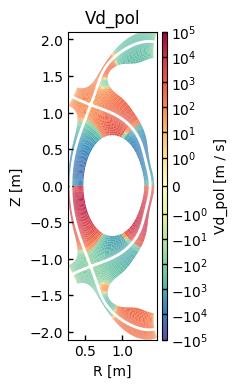

In [7]:
ds["Vd_pol"]=ds["Vd"]*abs(ds["Bpxy"] / abs(ds["Bxy"]))
fig, ax = plt.subplots()
ds["Vd_pol"].bout.polygon(ax = ax , cmap = "Spectral_r", antialias = True,logscale = True ,vmin= - 1e5, vmax=1e5)

## I love Link liu
Try to subtract variables that you think worth comparing, such as `Sd+_iz` `Edd+_cx` ...

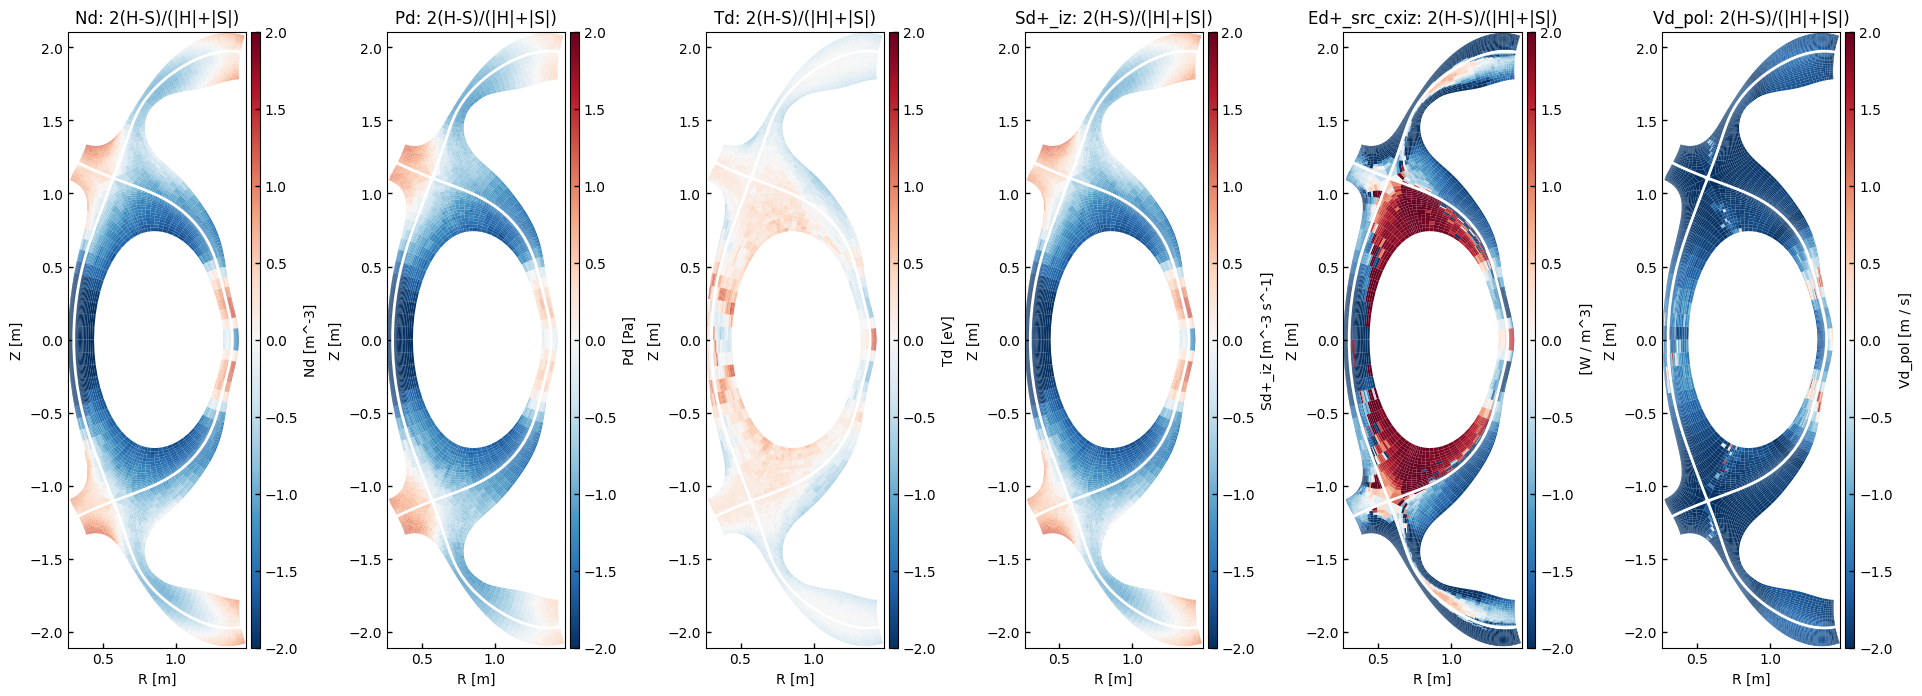

In [46]:
fields = {
    "Nd": (ds["Nd"], bal.bal["Na"]),
    # "Nd+": (ds["Nd+"], bal.bal["Nd+"]),
    "Pd": (ds["Pd"], bal.bal["Pa"]),
    "Td": (ds["Td"], bal.bal["Ta"]),
    "Sd+_iz" :(ds["Sd+_iz"], bal.bal["Sd+_iz"]),
    # "Sd+_rec" :(np.abs(ds["Sd+_rec"]), np.abs(bal.bal["Sd+_rec"])),

    # hermes-3 Edd+_cx is sink of ion, source of neutral;
    # SOLPS is energy source of ion due to ion-neutral collision (cx+iz)
    # To obtain ion energy source due to cx and iz (matching to solps's eirene_mc_eapl_shi_bal),
    # We should sum up Ed+_iz and negative Edd+_cx
    
    "Ed+_src_cxiz" :(ds["Ed+_iz"]-ds["Edd+_cx"], bal.bal["Edd+_cxiz"]),
    "Vd_pol": (np.abs(ds["Vd_pol"]), np.abs(Vd_pol))
}
pol_h = np.r_[2:72, 76:206] # poloidal: drop 0 1 , 72 73, 74 75 , 206 207
rad_h = np.r_[2:38]

pol_s = np.r_[1:71, 73:203] # poloidal: drop 0, 72, 73, 203
rad_s = np.r_[1:37]        # radial:   0, 37 are guard cell
# # print(pol_h, rad_h)    
# print(pol_s, rad_s)    
debug=False
symmetry=True #False
# fig, ax = plt.subplots(1, len(fields), figsize=(30, 60))
fig, ax = plt.subplots(1, len(fields), figsize=(4 * len(fields), 8))
for i, (field, (hdata, sdata)) in enumerate(fields.items()):
    # Handle with hermes-3 data
    h_guard = hdata.transpose("theta","x")
    # h_values = h_guard[pol_h, :][:, rad_h]

    # Handle with SOLPS data
    # s_values = sdata[pol_s,:][:, rad_s]
    h_values = np.asarray(h_guard[pol_h, :][:, rad_h])
    s_values = np.asarray(sdata[pol_s, :][:, rad_s])

    if debug:
        print(f"[H] {field}_guard shape: {h_guard.shape}")
        print(f"[H] {field}_values shape: {h_values.shape}")
        print(f"[S] {field}_guard shape :  {sdata.shape}")
        print(f"[S] {field}_values shape :  {s_values.shape}")

    if symmetry:
        # Symmetric relative difference, bounded in [-2, 2]
        rel = np.full(h_guard.shape, np.nan)
        denom = np.abs(h_values) + np.abs(s_values)
        rel[np.ix_(pol_h, rad_h)] = np.divide(
            2 * (h_values - s_values), denom,
            out=np.full_like(denom, np.nan), where=denom != 0,
        )
        diff_norm = h_guard.copy(data=rel)
        diff_norm.bout.polygon(ax=ax[i], cmap="RdBu_r", antialias=True,
                           logscale=False, vmin=-2, vmax=2, separatrix=True)
        ax[i].set_title(f"{field}: 2(H-S)/(|H|+|S|)")
    else:
        # Creat an array for subtraction result with hermes-3 shape
        diff_full_arr = np.full(hdata.transpose("theta","x").shape, np.nan)
        # Specify the location by ix and fill in the values into the array
        diff_full_arr[np.ix_(pol_h, rad_h)] = np.asarray(h_values) - np.asarray(s_values)

        print(f"Difference of {field} shape: {diff_full_arr.shape}")
        #  To get the full dataset for the arrary
        diff_full = hdata.transpose("theta", "x").copy(data=diff_full_arr) 
        diff_norm = diff_full/hdata.transpose("theta", "x")
        # diff_norm = diff_full/hdata.transpose("theta", "x")
        # diff_norm.bout.polygon(ax=ax, cmap="RdBu_r", antialias=True,
        diff_norm.bout.polygon(ax=ax[i], cmap="Spectral_r", antialias=True,
                    logscale=True, separatrix=True, )
        ax[i].set_title(f"{field}")



fig.savefig("diff.pdf")

## Knudsen number of the neutral atoms

$$\mathrm{Kn} = \frac{\lambda}{L}, \qquad \lambda = \frac{v_{th}}{\nu}, \qquad v_{th} = \sqrt{\frac{e\,T_a}{m_d}}, \qquad L = \frac{1}{|\nabla \ln f|}$$

- Fluid limit: $\mathrm{Kn} < 0.1$
- **Hermes-3**: $\nu = \nu_{cx} + \nu_{iz}$ = `Kd_Dnn_coll` $-$ `Kd_mfp_pseudo_coll` (mode `afn`, no n-n collisions).
  The pseudo term $v_{th}/$`neutral_lmax` caps $\lambda \le$ `neutral_lmax`, so it is removed for the physical Kn.
- **SOLPS** (independent of Hermes-3, only SOLPS quantities are used):
  - $\nu_{iz}$ = `Sd+_iz` / `Na`
  - $\nu_{cx} = n_i \langle\sigma v\rangle_{cx}(T_{eff})$, with $T_{eff} = (T_a + T_i)/2$ and AMJUEL H.2 3.1.8,
    i.e. the same rate definition Hermes-3 uses (`json_database/AMJUEL_H.2_3.1.8.json`, `include/rate_helper.hxx`).
    SOLPS has no CX frequency output, so this is a fluid-style diagnostic of the SOLPS solution, not EIRENE's internal rate.
  - Atom temperature $T_a$ (`Ta`), not `Td` = `Tn`, which mixes atoms and molecules.
- $L$ uses the distance between neighbouring cell centres in (R, Z). Steps across branch cuts are detected and ignored.
- Check: applying the same $\nu_{cx}$ formula to Hermes-3's own plasma should reproduce `Kdd+_cx`.

#### Helper functions for Kn

In [15]:
import warnings

DEUTERIUM_MASS_KG = 2 * 1.6726e-27
ELEMENTARY_CHARGE_C = 1.602e-19
DEUTERIUM_MASS_NUMBER = 2

# AMJUEL H.2 3.1.8 charge-exchange fit, same data Hermes-3 uses (json_database/AMJUEL_H.2_3.1.8.json)
# ln<sigma v> [cm3/s] = sum_n coefficient_n * (ln T)^n
AMJUEL_CX_COEFFICIENTS = [
    -1.850280000000e+01,
    3.708409000000e-01,
    7.949876000000e-03,
    -6.143769000000e-04,
    -4.698969000000e-04,
    -4.096807000000e-04,
    1.440382000000e-04,
    -1.514243000000e-05,
    5.122435000000e-07,
]
# Hermes-3 clamps Teff to this range before evaluating the fit (include/rate_helper.hxx)
CX_TEFF_MIN_EV = 0.01
CX_TEFF_MAX_EV = 1e4

# Guard-free index arrays, both give a (200, 36) grid
hermes_poloidal_index = np.r_[2:72, 76:206]
hermes_radial_index = np.r_[2:38]
solps_poloidal_index = np.r_[1:71, 73:203]
solps_radial_index = np.r_[1:37]


def thermal_speed(temperature_eV):
    """v_th = sqrt(e T / m_d) [m/s], same definition as Hermes-3 Dnn = v_th^2 / nu."""
    return np.sqrt(temperature_eV * ELEMENTARY_CHARGE_C / DEUTERIUM_MASS_KG)


def cx_effective_temperature(atom_temperature_eV, ion_temperature_eV):
    """Teff = sum over reactants of T / A, as in Hermes-3 calc_Teff [eV]."""
    return atom_temperature_eV / DEUTERIUM_MASS_NUMBER + ion_temperature_eV / DEUTERIUM_MASS_NUMBER


def cx_rate_coefficient(effective_temperature_eV):
    """<sigma v>_cx [m3/s] from AMJUEL H.2 3.1.8."""
    temperature = np.clip(np.asarray(effective_temperature_eV, dtype=float), CX_TEFF_MIN_EV, CX_TEFF_MAX_EV)
    log_temperature = np.log(temperature)
    log_sigma_v = np.zeros_like(log_temperature)
    for power, coefficient in enumerate(AMJUEL_CX_COEFFICIENTS):
        log_sigma_v += coefficient * log_temperature**power
    return np.exp(log_sigma_v) * 1e-6   # cm3/s -> m3/s


def cx_frequency(ion_density, atom_temperature_eV, ion_temperature_eV):
    """CX collision frequency seen by one atom: nu_cx = n_i <sigma v>_cx [1/s]."""
    effective_temperature = cx_effective_temperature(atom_temperature_eV, ion_temperature_eV)
    return np.asarray(ion_density, dtype=float) * cx_rate_coefficient(effective_temperature)


def log_derivative_along_axis(log_field, R, Z, axis, jump_factor):
    """d(ln f)/dl along one grid direction, at cell centres [1/m]."""
    # Put the chosen direction first so the rest of the code only handles axis 0
    log_field = np.moveaxis(log_field, axis, 0)
    R = np.moveaxis(R, axis, 0)
    Z = np.moveaxis(Z, axis, 0)

    # Slope between each cell and its next neighbour
    step_distance = np.hypot(np.diff(R, axis=0), np.diff(Z, axis=0))
    step_slope = np.diff(log_field, axis=0) / step_distance

    # A step much longer than the steps beside it jumps across a branch cut -> not a real neighbour
    previous_step = np.vstack([step_distance[:1], step_distance[:-1]])
    next_step = np.vstack([step_distance[1:], step_distance[-1:]])
    is_branch_cut = step_distance > jump_factor * np.minimum(previous_step, next_step)
    step_slope[is_branch_cut] = np.nan

    # Cell-centred slope = mean of the step before and the step after (ignoring missing ones)
    empty_row = np.full((1,) + step_slope.shape[1:], np.nan)
    slope_from_previous_cell = np.vstack([empty_row, step_slope])
    slope_to_next_cell = np.vstack([step_slope, empty_row])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        cell_slope = np.nanmean(np.stack([slope_from_previous_cell, slope_to_next_cell]), axis=0)

    return np.moveaxis(cell_slope, 0, axis)


def gradient_length(field, R, Z, jump_factor=2.0):
    """L = 1 / |grad ln(field)| [m] on a (poloidal, radial) grid of cell centres."""
    field = np.asarray(field, dtype=float)
    log_field = np.log(np.where(field > 0, field, np.nan))
    poloidal_slope = log_derivative_along_axis(log_field, np.asarray(R), np.asarray(Z), 0, jump_factor)
    radial_slope = log_derivative_along_axis(log_field, np.asarray(R), np.asarray(Z), 1, jump_factor)
    gradient_magnitude = np.sqrt(poloidal_slope**2 + radial_slope**2)
    with np.errstate(divide="ignore"):
        return 1.0 / gradient_magnitude


def knudsen_number(temperature_eV, collision_frequency, field_for_gradient, R, Z):
    """Return (Kn, mean free path, gradient length) as numpy arrays."""
    collision_frequency = np.asarray(collision_frequency, dtype=float)
    positive_frequency = np.where(collision_frequency > 0, collision_frequency, np.nan)
    mean_free_path = thermal_speed(np.asarray(temperature_eV, dtype=float)) / positive_frequency
    length_scale = gradient_length(field_for_gradient, R, Z)
    return mean_free_path / length_scale, mean_free_path, length_scale


def print_knudsen_summary(label, kn_values):
    kn_values = kn_values[np.isfinite(kn_values)]
    fluid_fraction = np.mean(kn_values < 0.1)
    print(f"{label:<28} median Kn = {np.median(kn_values):.3e},  cells with Kn < 0.1 = {100 * fluid_fraction:.1f} %")

In [16]:
gradient_field_name = "Nd"   # "Nd" or "Pd": which profile defines the gradient length L

# Unit check: collision frequencies must be in [s-1] (values ~1e2 - 1e6), not normalised
print("Kd_Dnn_coll units:", ds["Kd_Dnn_coll"].attrs.get("units"), "| max =", float(ds["Kd_Dnn_coll"].max()))
print("Td units:", ds["Td"].attrs.get("units"), "| Td+ units:", ds["Td+"].attrs.get("units"))

# ---------------- Hermes-3 ----------------
# All arrays as (theta, x) = (poloidal, radial), same layout as SOLPS
def hermes_array(variable):
    return np.asarray(variable.transpose("theta", "x"))

hermes_R = hermes_array(ds["R"])
hermes_Z = hermes_array(ds["Z"])
hermes_Td = hermes_array(ds["Td"])
hermes_total_frequency = hermes_array(ds["Kd_Dnn_coll"])                 # nu_cx + nu_iz + nu_pseudo
hermes_pseudo_frequency = hermes_array(ds["Kd_mfp_pseudo_coll"])         # v_th / neutral_lmax
hermes_physical_frequency = hermes_total_frequency - hermes_pseudo_frequency
hermes_gradient_field = hermes_array(ds[gradient_field_name])

hermes_kn, hermes_mfp, hermes_length = knudsen_number(
    hermes_Td, hermes_physical_frequency, hermes_gradient_field, hermes_R, hermes_Z)
hermes_kn_with_pseudo, _, _ = knudsen_number(
    hermes_Td, hermes_total_frequency, hermes_gradient_field, hermes_R, hermes_Z)

# Keep only the guard-free cells
hermes_inside = np.zeros(hermes_kn.shape, dtype=bool)
hermes_inside[np.ix_(hermes_poloidal_index, hermes_radial_index)] = True
hermes_kn[~hermes_inside] = np.nan
hermes_kn_with_pseudo[~hermes_inside] = np.nan

# ---------------- Check the CX formula against Hermes-3 ----------------
# Same formula on Hermes-3's own plasma should reproduce the Hermes-3 output Kdd+_cx (ratio ~ 1)
hermes_cx_from_formula = cx_frequency(hermes_array(ds["Nd+"]), hermes_Td, hermes_array(ds["Td+"]))
hermes_cx_output = hermes_array(ds["Kdd+_cx"])
cx_ratio = hermes_cx_from_formula[hermes_inside] / hermes_cx_output[hermes_inside]
print(f"\nCX check, formula / Kdd+_cx: median = {np.nanmedian(cx_ratio):.4f}, "
      f"min = {np.nanmin(cx_ratio):.4f}, max = {np.nanmax(cx_ratio):.4f}")

# ---------------- SOLPS (only SOLPS quantities) ----------------
solps_Ta = np.asarray(bal.bal["Ta"])          # atom temperature [eV] (not Td = Tn, which includes molecules)
solps_Ti = np.asarray(bal.bal["Td+"])         # ion temperature [eV]
solps_ni = np.asarray(bal.bal["Nd+"])         # ion density = Ne (quasi-neutrality)
solps_Na = np.asarray(bal.bal["Na"])

solps_iz_frequency = np.divide(np.abs(bal.bal["Sd+_iz"]), solps_Na,
                               out=np.full_like(solps_Na, np.nan), where=solps_Na > 0)
solps_cx_frequency = cx_frequency(solps_ni, solps_Ta, solps_Ti)

solps_physical_frequency = solps_cx_frequency + solps_iz_frequency
solps_kn, solps_mfp, solps_length = knudsen_number(
    solps_Ta, solps_physical_frequency, bal.bal[gradient_field_name], bal.g["R"], bal.g["Z"])

# Keep only the guard-free cells, same region as Hermes-3
solps_inside = np.zeros(solps_kn.shape, dtype=bool)
solps_inside[np.ix_(solps_poloidal_index, solps_radial_index)] = True
solps_kn[~solps_inside] = np.nan

# ---------------- Summary ----------------
print()
print_knudsen_summary("Hermes-3 (physical nu)", hermes_kn)
print_knudsen_summary("Hermes-3 (with pseudo nu)", hermes_kn_with_pseudo)
print_knudsen_summary("SOLPS", solps_kn)
print()
print(f"Median nu_cx:           Hermes-3 = {np.nanmedian(hermes_cx_output[hermes_inside]):.3e} 1/s, "
      f"SOLPS = {np.nanmedian(solps_cx_frequency[solps_inside]):.3e} 1/s")
print(f"Median mean free path:  Hermes-3 = {np.nanmedian(hermes_mfp[hermes_inside]):.3e} m, "
      f"SOLPS = {np.nanmedian(solps_mfp[solps_inside]):.3e} m")
print(f"Median gradient length: Hermes-3 = {np.nanmedian(hermes_length[hermes_inside]):.3e} m, "
      f"SOLPS = {np.nanmedian(solps_length[solps_inside]):.3e} m")

Kd_Dnn_coll units: s^-1 | max = 26615064620.079235
Td units: eV | Td+ units: eV

CX check, formula / Kdd+_cx: median = 1.0000, min = 1.0000, max = 1.0000

Hermes-3 (physical nu)       median Kn = 3.235e+00,  cells with Kn < 0.1 = 0.0 %
Hermes-3 (with pseudo nu)    median Kn = 8.500e-01,  cells with Kn < 0.1 = 0.3 %
SOLPS                        median Kn = 2.649e+00,  cells with Kn < 0.1 = 0.2 %

Median nu_cx:           Hermes-3 = 9.337e+04 1/s, SOLPS = 7.391e+04 1/s
Median mean free path:  Hermes-3 = 2.752e-01 m, SOLPS = 3.161e-01 m
Median gradient length: Hermes-3 = 8.467e-02 m, SOLPS = 1.100e-01 m


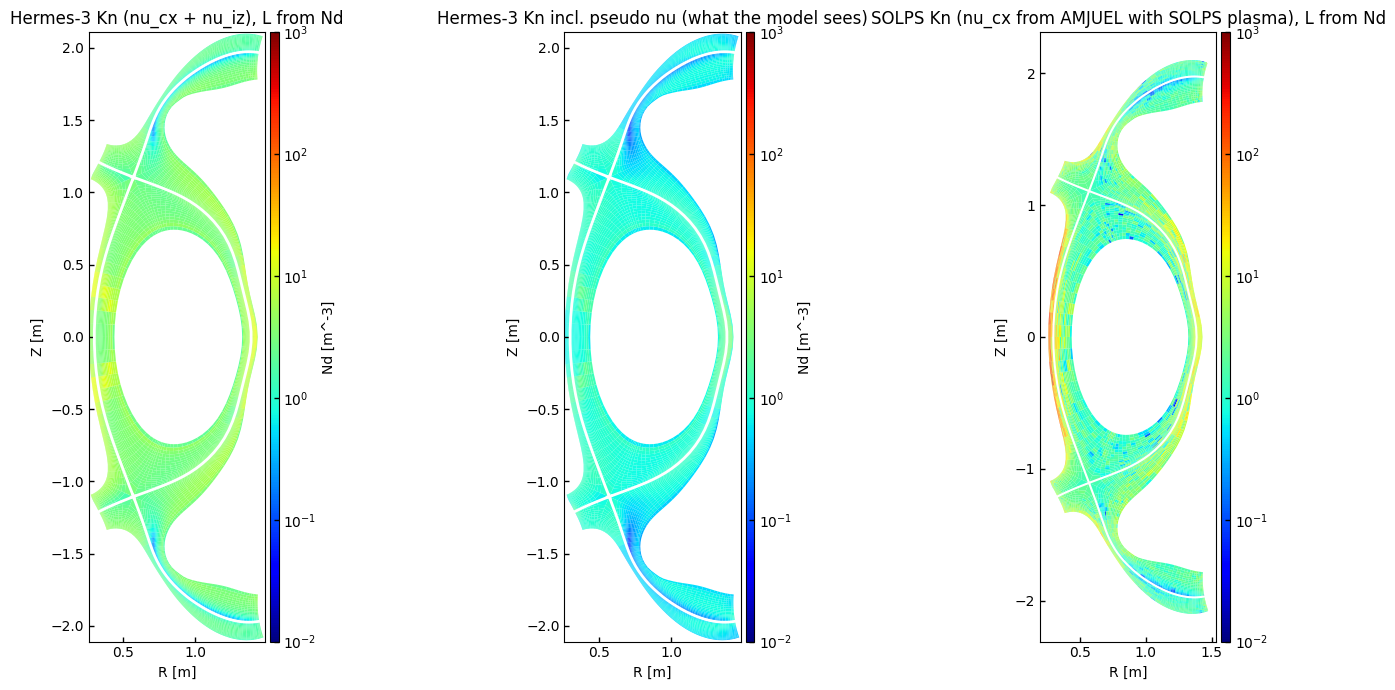

In [17]:
kn_min = 1e-2
kn_max = 1e3
hermes_template = ds["Nd"].transpose("theta", "x")

fig, ax = plt.subplots(1, 3, figsize=(15, 7))

hermes_template.copy(data=hermes_kn).bout.polygon(
    ax=ax[0], cmap="jet", antialias=True, logscale=True, vmin=kn_min, vmax=kn_max, separatrix=True)
ax[0].set_title(f"Hermes-3 Kn (nu_cx + nu_iz), L from {gradient_field_name}")

hermes_template.copy(data=hermes_kn_with_pseudo).bout.polygon(
    ax=ax[1], cmap="jet", antialias=True, logscale=True, vmin=kn_min, vmax=kn_max, separatrix=True)
ax[1].set_title("Hermes-3 Kn incl. pseudo nu (what the model sees)")

bal.plot_2d("Kn", ax=ax[2], data=solps_kn, cmap="jet", antialias=True,
            logscale=True, vmin=kn_min, vmax=kn_max, separatrix=True)
ax[2].set_title(f"SOLPS Kn (nu_cx from AMJUEL with SOLPS plasma), L from {gradient_field_name}")

fig.tight_layout()
fig.savefig(f"knudsen_number_{gradient_field_name}.pdf")